# SUNSHIELD — Notebook 4: Evaluation

**Place in Dr. Mai's workflow:** the last boxes of both drawings.

```
TRAINING:  Actual 0/1 ─┐
                       ├─► F1 for each k (+ confusion matrix) ─► Best k
        Predicted 0/1 ─┘

TESTING:   Actual 0/1 ─┐   (using the best k from training only)
                       ├─► F1 + confusion matrix ─► final test result
        Predicted 0/1 ─┘
```

The **actual** 0/1 is the reference (what really happened); the **predicted** 0/1 is what the model's line says.

| | Predicted 1 | Predicted 0 |
|---|---|---|
| **Actual 1** | TP — anomaly found | FN — anomaly missed |
| **Actual 0** | FP — false alarm | TN — normal, correctly normal |

| Step | What happens | Output |
|---|---|---|
| 1 | Training: for each k compare actual vs predicted 0/1 → TP, FP, FN, TN | metrics table |
| 2 | Training: precision, recall, F1 for each k | `metrics_all_k.csv` |
| 3 | Training: confusion matrix for each k | `confusion_matrices_train.png` |
| 4 | Choose the best k = highest training F1 | `best_k` |
| 5 | Validation: metrics + confusion matrix using the best k | validation results |
| 6 | Testing: metrics + confusion matrix using the best k from training | test results |
| 7 | Plot precision / recall / F1 vs k | `metrics_vs_k.png` |
| 8 | Save and zip outputs | `step4_outputs.zip` |

## Settings

In [1]:
import os, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

K_VALUES = [1, 1.5, 2, 2.5, 3]
SPLITS = ['train', 'val', 'test']
OUT_DIR = 'step4_outputs'
os.makedirs(OUT_DIR, exist_ok=True)

# Chart style (light surface, recessive grid, 2 px lines)
SURFACE, INK, INK_2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
BLUES = LinearSegmentedColormap.from_list('blues', ['#cde2fb', '#86b6ef', '#2a78d6', '#184f95', '#0d366b'])
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': GRID,
                     'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
                     'axes.titlecolor': INK, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
                     'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2,
                     'legend.frameon': False, 'font.size': 10})

## Upload Notebook 3 outputs

Run the cell below, click **Choose Files** and select `step3_outputs.zip`
(the file downloaded at the end of Notebook 3).

In [2]:
from google.colab import files
uploaded = files.upload()
shutil.unpack_archive(list(uploaded)[0], 'step3_outputs', 'zip')

anomalies = {s: pd.read_csv(f'step3_outputs/anomaly_{s}.csv', parse_dates=['DATE_TIME']) for s in SPLITS}
with open('step3_outputs/settings.txt') as f:
    print('Notebook 3 settings:\n' + f.read())
for s in SPLITS:
    print(f'{s:5s}: {len(anomalies[s]):,} readings')

Notebook 3 settings:
MODE = level
PRUNING = False
K_VALUES = [1, 1.5, 2, 2.5, 3]
MIN_HISTORY = 2

train: 36,491 readings
val  : 11,968 readings
test : 10,758 readings


## Helper functions

`evaluate` counts the 4 cases and computes the metrics:

$$\text{Precision} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN} \qquad
F1 = \frac{2 \cdot \text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

- **Precision:** of the readings the predicted line flags, how many are real anomalies (few false alarms = high).
- **Recall:** of the real anomalies, how many the predicted line also flags (few missed = high).
- **F1:** one number that balances both; this is what chooses k.

If a denominator is 0 (for example no reading flagged at all) the metric is set to 0.

In [3]:
def evaluate(df, k):
    actual = df[f'actual_anomaly_k{k:g}'].to_numpy()
    predicted = df[f'predicted_anomaly_k{k:g}'].to_numpy()
    tp = int(((actual == 1) & (predicted == 1)).sum())
    fp = int(((actual == 0) & (predicted == 1)).sum())
    fn = int(((actual == 1) & (predicted == 0)).sum())
    tn = int(((actual == 0) & (predicted == 0)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {'k': k, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'precision': precision, 'recall': recall, 'F1': f1}

def plot_confusion(ax, row, title):
    matrix = np.array([[row['TP'], row['FN']], [row['FP'], row['TN']]], dtype=int)
    ax.imshow(matrix, cmap=BLUES, vmin=0, vmax=matrix.max())
    ax.grid(False)
    for (i, j), value in np.ndenumerate(matrix):
        name = [['TP', 'FN'], ['FP', 'TN']][i][j]
        ax.text(j, i, f'{name}\n{value:,}', ha='center', va='center', fontsize=10,
                color=SURFACE if value > matrix.max() / 2 else INK)
    ax.set_xticks([0, 1], ['Anomaly (1)', 'Normal (0)'])
    ax.set_yticks([0, 1], ['Anomaly (1)', 'Normal (0)'])
    ax.set_xlabel('Predicted line')
    ax.set_ylabel('Actual line')
    ax.set_title(title, loc='left', fontsize=10)

## Steps 1 and 2 — Training: TP, FP, FN, TN, precision, recall and F1 for each k

In [4]:
train_metrics = pd.DataFrame([evaluate(anomalies['train'], k) for k in K_VALUES]).set_index('k')
train_metrics.to_csv(os.path.join(OUT_DIR, 'metrics_all_k.csv'))
train_metrics.round(4)

,TP,FP,FN,TN,precision,recall,F1
k,,,,,,,
1.0,11441,4347,3993,16710,0.7247,0.7413,0.7329
1.5,1990,1902,2308,30291,0.5113,0.4630,0.4860
2.0,580,158,617,35136,0.7859,0.4845,0.5995
2.5,344,14,62,36071,0.9609,0.8473,0.9005
3.0,176,43,2,36270,0.8037,0.9888,0.8866


## Step 3 — Training: confusion matrix for each k

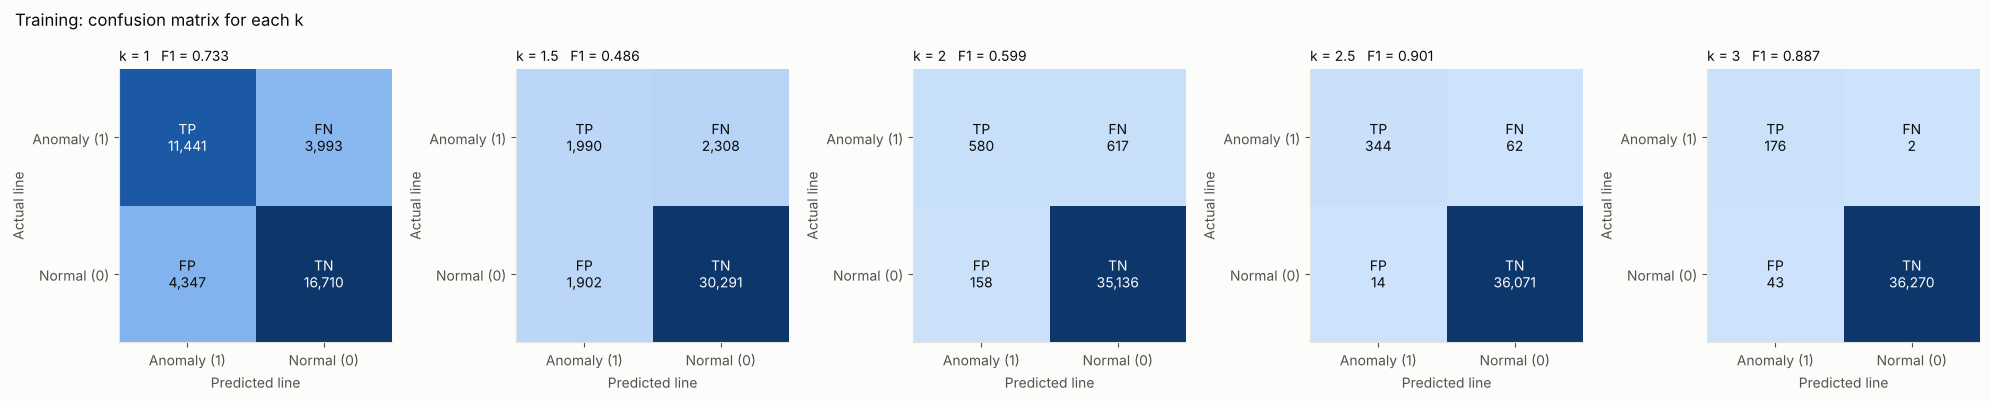

In [5]:
fig, axes = plt.subplots(1, len(K_VALUES), figsize=(4 * len(K_VALUES), 4))
for ax, k in zip(axes, K_VALUES):
    plot_confusion(ax, train_metrics.loc[k], f'k = {k:g}   F1 = {train_metrics.loc[k, "F1"]:.3f}')
fig.suptitle('Training: confusion matrix for each k', x=0.01, ha='left', color=INK)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'confusion_matrices_train.png'), dpi=150)
plt.show()

## Step 4 — Choose the best k = highest training F1

Only the **training** results are used. Validation and test are not looked at when choosing k.
If two k values had exactly the same F1, the smaller k would be kept.

In [6]:
best_k = float(train_metrics['F1'].idxmax())
with open(os.path.join(OUT_DIR, 'best_k.txt'), 'w') as f:
    f.write(f'best_k = {best_k:g}\ntraining F1 = {train_metrics.loc[best_k, "F1"]:.4f}\n')
print(f'Best k = {best_k:g}  (training F1 = {train_metrics.loc[best_k, "F1"]:.4f})')

Best k = 2.5  (training F1 = 0.9005)


## Steps 5 and 6 — Validation and testing with the best k from training

The same best k is used as it is — nothing is tuned on validation or test.
The test result is the **final result** of the model.

In [7]:
results = pd.DataFrame([{'split': s, **evaluate(anomalies[s], best_k)} for s in SPLITS]).set_index('split')
results.to_csv(os.path.join(OUT_DIR, 'results_best_k.csv'))
print(f'Results with the best k = {best_k:g}:')
results.round(4)

Results with the best k = 2.5:


,k,TP,FP,FN,TN,precision,recall,F1
split,,,,,,,,
train,2.5,344,14,62,36071,0.9609,0.8473,0.9005
val,2.5,195,69,48,11656,0.7386,0.8025,0.7692
test,2.5,159,39,99,10461,0.8030,0.6163,0.6974


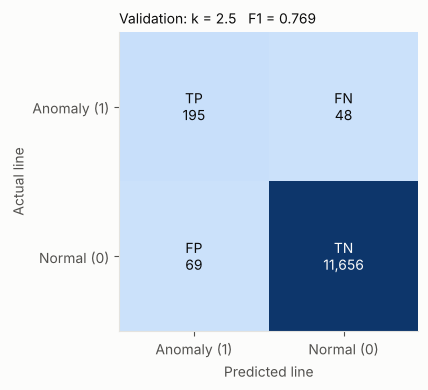

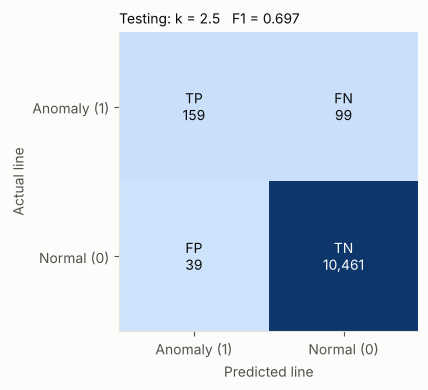

In [8]:
for split, label in [('val', 'Validation'), ('test', 'Testing')]:
    fig, ax = plt.subplots(figsize=(4.5, 4))
    plot_confusion(ax, results.loc[split], f'{label}: k = {best_k:g}   F1 = {results.loc[split, "F1"]:.3f}')
    fig.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, f'confusion_matrix_{split}.png'), dpi=150)
    plt.show()

## Step 7 — Precision, recall and F1 vs k (training)

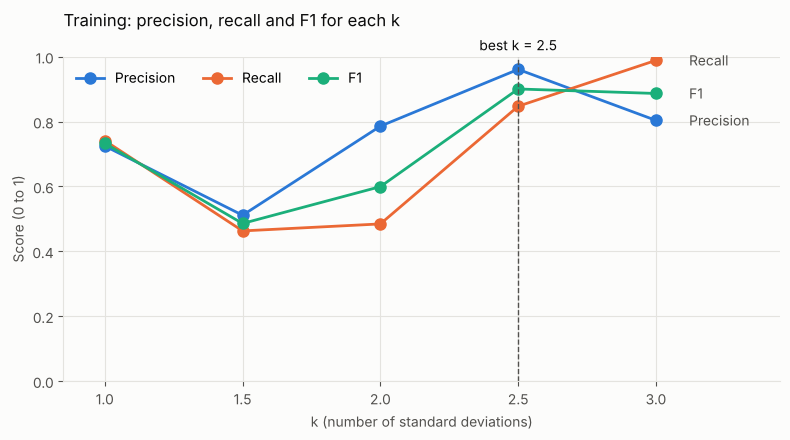

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
series = [('precision', 'Precision', BLUE), ('recall', 'Recall', ORANGE), ('F1', 'F1', AQUA)]
for column, label, color in series:
    ax.plot(K_VALUES, train_metrics[column], color=color, marker='o', markersize=8, label=label)

# Direct labels at the right end, pushed apart so they never overlap
ends = sorted(((train_metrics[c].iloc[-1], l, col) for c, l, col in series), key=lambda e: e[0])
min_gap, placed = 0.05, []
for y, label, color in ends:
    y_label = max(y, placed[-1] + min_gap) if placed else y
    placed.append(y_label)
    ax.annotate(label, (K_VALUES[-1], y), xytext=(K_VALUES[-1] + 0.12, y_label), color=INK_2, va='center')

ax.axvline(best_k, color=INK_2, linestyle='--', linewidth=1)
ax.annotate(f'best k = {best_k:g}', (best_k, 1.02), xycoords=('data', 'axes fraction'), ha='center', color=INK)
ax.set_xticks(K_VALUES)
ax.set_xlim(K_VALUES[0] - 0.15, K_VALUES[-1] + 0.45)
ax.set_ylim(0, 1)
ax.set_xlabel('k (number of standard deviations)')
ax.set_ylabel('Score (0 to 1)')
ax.set_title('Training: precision, recall and F1 for each k', loc='left', pad=22)
ax.legend(loc='upper left', ncol=3)
fig.tight_layout()
fig.savefig(os.path.join(OUT_DIR, 'metrics_vs_k.png'), dpi=150)
plt.show()

## Step 8 — Save and zip outputs

| File | Content |
|---|---|
| `metrics_all_k.csv` | training TP, FP, FN, TN, precision, recall, F1 for every k |
| `confusion_matrices_train.png` | training confusion matrix for every k |
| `best_k.txt` | chosen k and its training F1 |
| `results_best_k.csv` | train / validation / test metrics with the best k |
| `confusion_matrix_val.png`, `confusion_matrix_test.png` | validation and test confusion matrices |
| `metrics_vs_k.png` | precision / recall / F1 vs k |

In [10]:
shutil.make_archive('step4_outputs', 'zip', OUT_DIR)
for f in sorted(os.listdir(OUT_DIR)):
    print(f'{f:30s} {os.path.getsize(os.path.join(OUT_DIR, f)) / 1e6:6.2f} MB')

files.download('step4_outputs.zip')

best_k.txt                       0.00 MB
confusion_matrices_train.png     0.11 MB
confusion_matrix_test.png        0.03 MB
confusion_matrix_val.png         0.03 MB
metrics_all_k.csv                0.00 MB
metrics_vs_k.png                 0.09 MB
results_best_k.csv               0.00 MB
